# 02 — Exploratory data analysis

**Mini Project 2.** Workk though the SA2, look at the variables individually - check ranges, distributions, relationships, spatial structure, and missing data including the
suppression problem. Getting to a  feature list that I use in clustering and classification steps of analysis.


## Setup

In [1]:
#import sys
#!{sys.executable} -m pip install geopandas shapely fiona pyproj

In [2]:
from pathlib import Path
import json
from pathlib import Path
OUT = Path("..") / "outputs"
threshold = json.loads((OUT / "frame_meta.json").read_text())["top_quartile_threshold"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd
import libpysal
import esda
print("All spatial packages loaded successfully!")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

OUT = Path("..") / "outputs"
analysis = pd.read_csv(OUT / "analysis_frame.csv")

print("rows, columns:", analysis.shape)
print()
print(analysis.dtypes.value_counts().to_string())
print()
print(analysis[["sa2_code", "sa2_name", "crowding_rate",
                "crowded_top_quartile"]].head(10).to_string(index=False))


All spatial packages loaded successfully!
rows, columns: (2395, 93)

float64    91
int64       1
str         1

 sa2_code             sa2_name  crowding_rate  crowded_top_quartile
   187600                Tiroa       0.000000                   0.0
   223400             Mowhanau       0.012270                   0.0
   101801            Whakarara       0.114286                   1.0
   174701               Okauia       0.025641                   0.0
   256600  Homebush-Te Ore Ore       0.028571                   0.0
   309300       Westport Rural       0.022346                   0.0
   357601           Whitestone       0.012658                   0.0
   313400               Loburn       0.029630                   0.0
   360500 West Plains-Makarewa       0.030769                   0.0
   151700         Waiheke East       0.043165                   0.0


In [3]:
#full distribution
#define a binary threshold could be national average (6%), but almost every SA2 fall below it. 95% negatives ie the model predicts not crowded every time it scares, so not useful.
#3 picked a threshold or a cut at the top quartiles 25% positive, 75% negative - enogh positive cases for recall and PR-AUC to mean something.

print(analysis["crowding_rate"].describe().round(4).to_string())
print()
print("usable   :", analysis["crowding_rate"].notna().sum(), "of", len(analysis))
print("quartiles:", analysis["crowded_top_quartile"].value_counts(dropna=False).to_string())


count    2283.0000
mean        0.0641
std         0.0650
min         0.0000
25%         0.0273
50%         0.0449
75%         0.0775
max         1.0000

usable   : 2283 of 2395
quartiles: crowded_top_quartile
0.0    1711
1.0     572
NaN     112


Threshold: top quartile of the SA2 crowding rate (≥ 7.75%). Chosen over an absolute threshold because a national-average cut would leave the positive class at roughly 6% and make recall and PR-AUC uninformative. The quartile gives a 25% positive class and mirrors the client's use — ranking areas for need assessment rather than labelling them crowded or not.

In [4]:
threshold = analysis["crowding_rate"].quantile(0.75)

print(f"threshold      : {threshold:.4f}")
print(f"positive class : {int(analysis['crowded_top_quartile'].sum())} SA2s")
print(f"base rate      : {analysis['crowded_top_quartile'].mean():.2%}")
print(f"majority-class accuracy: "
      f"{max(analysis['crowded_top_quartile'].mean(), 1 - analysis['crowded_top_quartile'].mean()):.2%}")


threshold      : 0.0775
positive class : 572 SA2s
base rate      : 25.05%
majority-class accuracy: 74.95%


In [5]:
#examining the max of 1. An SA2 where every houshold is crowded, or a data aritifact.
print(analysis.nlargest(8, "crowding_rate")[
    ["sa2_name", "crowded_count", "crowding_base", "crowding_rate"]
].to_string(index=False))


                          sa2_name  crowded_count  crowding_base  crowding_rate
                         Fiordland            3.0            3.0       1.000000
Islands Thames-Coromandel District            3.0            3.0       1.000000
               Takanini Industrial            3.0            6.0       0.500000
                      Wesley South            6.0           12.0       0.500000
                     Rongomai West          186.0          447.0       0.416107
                          Ferguson          234.0          570.0       0.410526
                        Ōtara West          243.0          612.0       0.397059
                      Māngere West          264.0          675.0       0.391111


In Code block 4 the top rows have bases of 3, 6 or 9 households, the  rare is real but it does not tell us accurately about the areas housing situation. These SA2 statistically squew — An SA2 with 9 households where 1 is crowded shows 11.1%; move that one household and it's 0% or 22%. This impacts the analysis because treating SA2s as equally-weighted units biases results toward areas with very small household counts. Should probably filter out maybe - minumum sise filter for SA2?. This is a limitation in my data I need to document.. This impacts the analysis because treating SA2s as equally-weighted units biases results toward areas with very small household counts.. Should probably filter out maybe - minumum sise filter for SA2?. This is a limitation in my data I need to document.

In [6]:
small = analysis["crowding_base"] < 20
print("SA2s under 20 households:", small.sum())
print("their crowding rate range:", 
      f"{analysis.loc[small,'crowding_rate'].min():.3f} to {analysis.loc[small,'crowding_rate'].max():.3f}")
print()
print("SA2s under 50 households:", (analysis['crowding_base'] < 50).sum())
print("SA2s under 100 households:", (analysis['crowding_base'] < 100).sum())
print()
print(analysis.nsmallest(12, "crowding_base")[
    ["sa2_name", "crowded_count", "crowding_base", "crowding_rate"]
].to_string(index=False))


SA2s under 20 households: 21
their crowding rate range: 0.000 to 1.000

SA2s under 50 households: 51
SA2s under 100 households: 82

                          sa2_name  crowded_count  crowding_base  crowding_rate
       Oceanic Waikato Region East            0.0            0.0            NaN
           Inlet Waitemata Harbour            0.0            0.0            NaN
         Oceanic West Coast Region            0.0            3.0            0.0
                         Fiordland            3.0            3.0            1.0
             Inlets other Auckland            0.0            3.0            0.0
Islands Thames-Coromandel District            3.0            3.0            1.0
                Inlets Nelson City            0.0            3.0            0.0
               Takanini Industrial            3.0            6.0            0.5
           Inlet Whangārei Harbour            0.0            6.0            0.0
               Bays Waiheke Island            0.0            6.0    

In Code block 5 - working out how many SA2 have small counts or bases.


In [7]:
#look at the most crowded areas:
print(analysis.nlargest(15, "crowding_rate")[
    ["sa2_name", "crowded_count", "crowding_base", "crowding_rate"]
].to_string(index=False))


                          sa2_name  crowded_count  crowding_base  crowding_rate
                         Fiordland            3.0            3.0       1.000000
Islands Thames-Coromandel District            3.0            3.0       1.000000
               Takanini Industrial            3.0            6.0       0.500000
                      Wesley South            6.0           12.0       0.500000
                     Rongomai West          186.0          447.0       0.416107
                          Ferguson          234.0          570.0       0.410526
                        Ōtara West          243.0          612.0       0.397059
                      Māngere West          264.0          675.0       0.391111
                     Harania North          279.0          720.0       0.387500
                        Ōtara East          288.0          753.0       0.382470
                       Ōtara South          210.0          573.0       0.366492
                       Sutton Park      

Code 6  looking ar the largest crowding rates and comparing it against the base. 

## Understanding what crowding is in the data set.

The crowding index comes in levels; needing a yes it is crowded no it is not crowded stament requires, how to collapse them  and determines the class balance, which
determines the metric, which determines everything downstream.

- [ ] Print the level distribution as counts and percentages
- [ ] Choose a binary threshold and state the reason in one sentence
- [ ] Print the resulting base rate

In [8]:
# The crowding index has seven categories. Show them before collapsing.
crowding_categories = [c for c in analysis.columns if c.startswith("household_crowding_index")]

counts = analysis[crowding_categories].sum()
shares = (counts / counts["household_crowding_index_total_stated"] * 100).round(2)

levels = pd.DataFrame({"households": counts.round(0), "percent": shares})
print(levels.to_string())
print()
print("total stated :", f"{counts['household_crowding_index_total_stated']:,.0f}")
print("not stated   :", f"{counts['household_crowding_index_not_stated']:,.0f}")


                                                                       households  percent
household_crowding_index_crowded                                         105633.0     6.20
household_crowding_index_two_or_more_bedrooms_needed_severely_crowded     30861.0     1.81
household_crowding_index_one_bedroom_needed_crowded                       74730.0     4.38
household_crowding_index_not_crowded                                    1598841.0    93.80
household_crowding_index_no_bedrooms_needed_and_none_spare               362940.0    21.29
household_crowding_index_one_bedroom_spare                               548877.0    32.20
household_crowding_index_two_or_more_bedrooms_spare                      686799.0    40.29
household_crowding_index_not_stated                                       75984.0     4.46
household_crowding_index_total                                          1780530.0   104.46
household_crowding_index_total_stated                                   1704474.0   100.00

Definition. Stats NZ uses the Canadian National Occupancy Standard (CNOS) to measure household crowding. This standard calculates the number of bedrooms needed based on the household's composition, ensuring that there should be no more than two people per bedroom. However, couples and children of certain ages can share a bedroom. The CNOS is adapted for a gender-based response, which is important for accurate data collection. The measure is used to provide insight into how people live in their homes, whether they have spare bedrooms or need more. s
ancy Standard. Stats NZ publishes this as a single aggregate (crowded) alongside its two parts — Two or more bedrooms needed (severely crowded) and One bedroom needed (crowded). I use the aggregate, which equals the two parts summed (to within base-3 rounding).

Denominator. total stated — the households that gave a usable answer. Dividing by total would include not stated and understate the rate wherever non-response is higher.

Why not the raw rate as a binary. Crowding is rare — around 6% nationally — so a "crowded / not crowded" split at SA2 level would be almost entirely zeros and any PR-AUC on it would be close to meaningless.

The threshold. Top quartile of the SA2 crowding rate. This gives a positive class of 25%, which is workable for the classifier, and it matches what the client does with the result — rank areas for assessment rather than label them.

In [9]:
crowding = [c for c in analysis.columns if c.startswith("household_crowding_index")]

counts  = analysis[crowding].sum()
stated  = counts["household_crowding_index_total_stated"]

levels = pd.DataFrame({
    "households": counts.round(0),
    "percent_of_stated": (counts / stated * 100).round(2),
})
print(levels.to_string())
print()
print(f"total stated : {stated:,.0f}")
print(f"total        : {counts['household_crowding_index_total']:,.0f}")


                                                                       households  percent_of_stated
household_crowding_index_crowded                                         105633.0               6.20
household_crowding_index_two_or_more_bedrooms_needed_severely_crowded     30861.0               1.81
household_crowding_index_one_bedroom_needed_crowded                       74730.0               4.38
household_crowding_index_not_crowded                                    1598841.0              93.80
household_crowding_index_no_bedrooms_needed_and_none_spare               362940.0              21.29
household_crowding_index_one_bedroom_spare                               548877.0              32.20
household_crowding_index_two_or_more_bedrooms_spare                      686799.0              40.29
household_crowding_index_not_stated                                       75984.0               4.46
household_crowding_index_total                                          1780530.0          

The two aggregates used here were validated in notebook 01: crowded equals its two components and total equals stated + not stated, both to within base-3 rounding. That check is why these three columns are trusted as the definition.

In [10]:
print("collapsed target: crowded (one or more bedrooms needed)")
print(f"  crowded households     : {counts['household_crowding_index_crowded']:>10,.0f}")
print(f"  of stated              : {counts['household_crowding_index_crowded']/stated:>10.2%}")
print(f"  not crowded households : {counts['household_crowding_index_not_crowded']:>10,.0f}")


collapsed target: crowded (one or more bedrooms needed)
  crowded households     :    105,633
  of stated              :      6.20%
  not crowded households :  1,598,841


## Univariate distributions

In [11]:
numeric_features = [c for c in analysis.columns
                    if c.startswith(("tenure_of_household", "total_household_income",
                                     "number_of_motor_vehicles", "household_composition",
                                     "sector_of_landlord", "access_to_telecommunication_systems",
                                     "number_of_usual_residents"))]

summary = analysis[numeric_features].describe().T[["count", "mean", "std", "min", "50%", "max"]]
summary["missing"] = analysis[numeric_features].isna().sum()
print(summary.round(2).to_string())


                                                                                                                  count      mean       std      min      50%       max  missing
access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems                       2276.0      8.50      8.10      0.0      6.0      93.0      119
access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone                           2278.0    668.49    321.17      6.0    654.0    1974.0      117
access_to_telecommunication_systems_total_responses_access_to_a_telephone                                        2276.0    221.59    120.20      0.0    213.0     963.0      119
access_to_telecommunication_systems_total_responses_access_to_a_fax_machine                                      2395.0   -997.00      0.00   -997.0   -997.0    -997.0        0
access_to_telecommunication_systems_total_responses_access_to_the_internet                                       22

One concern is this feature :

 - access_to_telecommunication_systems_total_responses_access_to_a_fax_machine
 - count 2395.0   mean -997.0   min -997.0   50% -997.0   max -997.0   missing 0

Every value is -997, which is why missing is 0 — my read_measure for suppressed SA2's, only strips -999, so -997 was passed through as a real number.

What -997 means: it's Stats NZ's other special value — a category that doesn't apply or isn't collected for the areas in that table. "Access to a fax machine" was dropped from the 2023 questionnaire, so every SA2 carries -997 for it. It is not a count and must not go into any model.

The fix — treat any large negative as mis datahon




this to use to filter at some point before creating modelling data.
MIN_HOUSEHOLDS = 50

analysis["meets_min_size"] = analysis["crowding_base"] >= MIN_HOUSEHOLDS
kept = analysis["meets_min_size"] & analysis["crowding_rate"].notna()

print(f"kept     : {kept.sum():,} SA2s  ({kept.mean():.1%} of all areas)")
print(f"dropped  : {(~kept).sum():,}  (small or suppressed)")
print(f"coverage : {analysis.loc[kept,'crowding_base'].sum() / analysis['crowding_base'].sum():.1%} of all stated households")
print()
print("dropped for small size only :",
      int((~analysis['meets_min_size'] & analysis['crowding_rate'].notna()).sum()))
print("dropped for suppression only:",
      int((analysis['meets_min_size'] & analysis['crowding_rate'].isna()).sum()))
print("dropped for both            :",
      int((~analysis['meets_min_size'] & analysis['crowding_rate'].isna()).sum()))


In [12]:
# any Stats NZ sentinel: -997 and -999 and anything else in that range
numeric = [c for c in analysis.columns
           if c not in ("sa2_code", "sa2_name") and analysis[c].dtype == "float64"]
analysis[numeric] = analysis[numeric].mask(analysis[numeric] <= -990)
analysis = analysis.copy()

print("columns still holding negatives:",
      int((analysis[numeric] < 0).any().sum()))
print("cells now missing:", int(analysis[numeric].isna().sum().sum()))


columns still holding negatives: 0
cells now missing: 12561


In [13]:
#check that there are no other values like this
all_missing = [c for c in numeric if analysis[c].isna().all()]
print(f"{len(all_missing)} columns are entirely missing and will be dropped:")
for c in all_missing:
    print("   ", c)

analysis = analysis.drop(columns=all_missing)
print()
print("frame now:", analysis.shape)


1 columns are entirely missing and will be dropped:
    access_to_telecommunication_systems_total_responses_access_to_a_fax_machine

frame now: (2395, 92)


In [14]:
#now I need to re run the distribution code to without the -997 numbers
numeric_features = [c for c in analysis.columns
                    if c.startswith(("tenure_of_household", "total_household_income",
                                     "number_of_motor_vehicles", "household_composition",
                                     "sector_of_landlord",
                                     "access_to_telecommunication_systems",
                                     "number_of_usual_residents"))]

summary = (analysis[numeric_features].describe().T[["count", "mean", "std", "min", "50%", "max"]])
summary["missing"] = analysis[numeric_features].isna().sum()
print(summary.round(2).to_string())


                                                                                                                  count      mean       std      min      50%       max  missing
access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems                       2276.0      8.50      8.10      0.0      6.0      93.0      119
access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone                           2278.0    668.49    321.17      6.0    654.0    1974.0      117
access_to_telecommunication_systems_total_responses_access_to_a_telephone                                        2276.0    221.59    120.20      0.0    213.0     963.0      119
access_to_telecommunication_systems_total_responses_access_to_the_internet                                       2278.0    647.02    317.47      0.0    630.0    1932.0      117
access_to_telecommunication_systems_total_responses_not_elsewhere_included                                       22

### Sentinel values mapped to missing

Stats NZ writes special values into the measure columns: `-999` for a
suppressed cell, and `-997` for a category not collected or not applicable.

Neither is a count. Left in place, `-999` produces a negative column total and
`-997` makes an all-missing column look complete. Both are mapped to missing
here, and the mask is written as `<= -990` so it catches any sibling sentinel
without my having to enumerate them.

**Found by:** the reconciliation check in notebook 01, where the crowding
index summed to a negat -997 was found in 02 during EDA. I had assumed that the only -ve numbers would be for the SA2 that were being suppressed.ive number.


## TODO — correlations and redundant features

Look for pairs that carry the same information, and for anything that would
make a coefficient uninterpretable.

- [ ] Correlation heatmap of the numeric features
- [ ] List every pair above your threshold (0.8? 0.9?) and decide what to do
- [ ] Outliers: which SA2s, and are they real or coding errors?

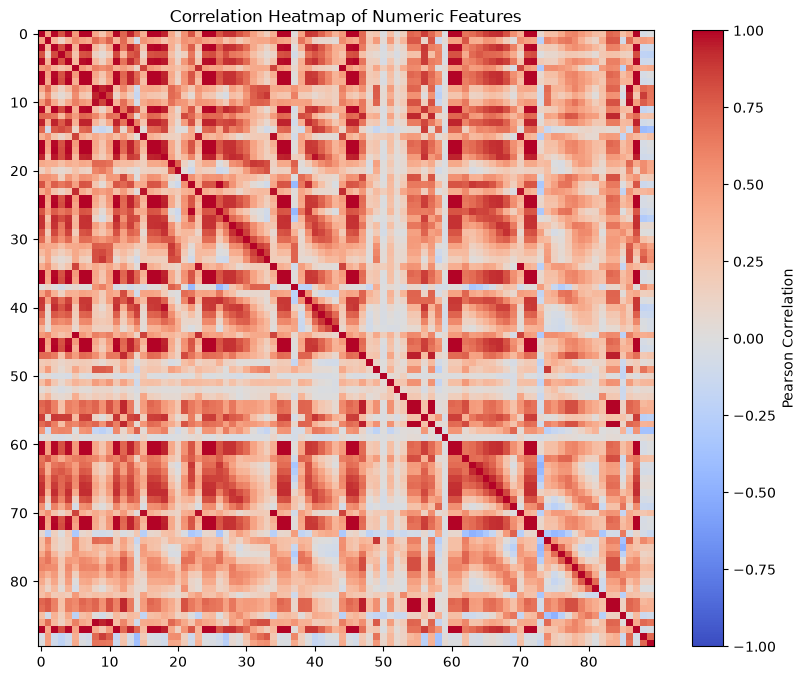

In [15]:
#this is an redo attempt
# Select your numeric columns (excluding codes/names)
numeric_cols = analysis.select_dtypes(include=[np.number]).columns
numeric_cols = [c for c in numeric_cols if c not in ['sa2_code']]

# Compute the correlation matrix
corr_matrix = analysis[numeric_cols].corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Pearson Correlation')
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

In [16]:
#this is a redo attempt 
threshold = 0.85

# Grab the upper triangle of the correlation matrix to avoid duplicates (A-B and B-A)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Filter pairs above threshold
high_corr_pairs = []
for col in upper_tri.columns:
    for idx in upper_tri.index:
        val = upper_tri.loc[idx, col]
        if abs(val) > threshold:
            high_corr_pairs.append((idx, col, val))

# Convert to a tidy DataFrame and sort highest to lowest
redundant_df = pd.DataFrame(high_corr_pairs, columns=['Feature 1', 'Feature 2', 'Correlation'])
redundant_df = redundant_df.sort_values(by='Correlation', ascending=False)

print(f"Found {len(redundant_df)} pairs with absolute correlation > {threshold}:")
display(redundant_df.head(20))

Found 443 pairs with absolute correlation > 0.85:


,Feature 1,Feature 2,Correlation
3,count_of_households_in_occupied_private_dwelli...,access_to_telecommunication_systems_total_resp...,1.0
411,household_crowding_index_crowded,crowded_count,1.0
28,access_to_telecommunication_systems_total_resp...,household_crowding_index_total,1.0
422,household_crowding_index_total_stated,crowding_base,1.0
54,access_to_telecommunication_systems_total_resp...,household_composition_total,1.0
402,sector_of_landlord_total,weekly_rent_paid_by_household_total,1.0
106,count_of_households_in_occupied_private_dwelli...,number_of_usual_residents_in_household_total,1.0
116,household_composition_total,number_of_usual_residents_in_household_total,1.0
113,household_crowding_index_total,number_of_usual_residents_in_household_total,1.0
109,access_to_telecommunication_systems_total_resp...,number_of_usual_residents_in_household_total,1.0


### How to decide what to do with them:
- Direct Redundancies (Correlation $\approx 1.0$): If two columns carry the exact same information (or one is just a sub-category that perfectly tracks the total), drop one of them. Keeping both introduces severe multicollinearity.
 - Totals vs. Breakdown: If you have a total column (e.g., Total Households) and multiple breakdown columns (e.g., Rented, Owned), the breakdown columns sum to the total. If you are building regression models later, you should either keep the breakdown and drop the total, or vice versa.

In [17]:
# List of pure structural totals that duplicate household counts
totals_to_drop = [
    'household_composition_total',
    'tenure_of_household_total',
    'household_crowding_index_total',
    'household_crowding_index_total_stated',
    'access_to_telecommunication_systems_total_stated',
    'number_of_motor_vehicles_total',
    'number_of_usual_residents_in_household_total',
    'sector_of_landlord_total',
    'weekly_rent_paid_by_household_total',
    'total_household_income_total',
    'crowding_base'
]

# Drop them from your analysis dataset (only drop those that actually exist in your columns)
cols_to_drop_actual = [c for c in totals_to_drop if c in analysis.columns]
analysis_cleaned = analysis.drop(columns=cols_to_drop_actual)

print(f"Dropped {len(cols_to_drop_actual)} redundant total columns.")
print(f"Remaining feature count: {analysis_cleaned.select_dtypes(include=[np.number]).shape[1]}")

Dropped 10 redundant total columns.
Remaining feature count: 81


In [18]:
#dropping duplicates 
# Drop exact structural duplicates where two columns represent the exact same metric
exact_duplicates_to_drop = [
    'crowded_count',  # Exact duplicate of household_crowding_index_crowded (keep one)
]

# Safely drop only columns that exist in the dataframe
cols_to_drop_step2 = [c for c in exact_duplicates_to_drop if c in analysis_cleaned.columns]
analysis_cleaned = analysis_cleaned.drop(columns=cols_to_drop_step2)

print(f"Dropped {len(cols_to_drop_step2)} exact duplicate columns.")

Dropped 1 exact duplicate columns.


In [19]:
from sklearn.preprocessing import StandardScaler

# 1. Isolate final numeric feature columns (exclude codes, names, or target variables)
exclude_cols = ['sa2_code', 'sa2_name', 'target'] # Adjust 'target' if your label column has a different name
feature_cols = [c for c in analysis_cleaned.select_dtypes(include=[np.number]).columns if c not in exclude_cols]

# 2. Handle any unexpected NaNs before scaling (fill with median or drop)
X_data = analysis_cleaned[feature_cols].fillna(analysis_cleaned[feature_cols].median())

# 3. Apply StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_data)

# Convert back to a clean DataFrame for modeling use
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols, index=analysis_cleaned.index)

print(f"Successfully scaled {X_scaled_df.shape[1]} features for interpretable modeling!")

Successfully scaled 79 features for interpretable modeling!


In [20]:
# 1. Check the dimensions (number of rows and columns) of your cleaned dataset
print(f"Dataset Shape: {analysis_cleaned.shape[0]} rows, {analysis_cleaned.shape[1]} columns")

# 2. Display the list of remaining columns so you can verify what's left
print("\nRemaining Columns:")
for col in analysis_cleaned.columns:
    print(f" - {col}")

# 3. Preview the first 5 rows
display(analysis_cleaned.head())

Dataset Shape: 2395 rows, 81 columns

Remaining Columns:
 - sa2_code
 - sa2_name
 - count_of_households_in_occupied_private_dwellings_total
 - access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems
 - access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone
 - access_to_telecommunication_systems_total_responses_access_to_a_telephone
 - access_to_telecommunication_systems_total_responses_access_to_the_internet
 - access_to_telecommunication_systems_total_responses_not_elsewhere_included
 - access_to_telecommunication_systems_total_responses_total
 - access_to_telecommunication_systems_total_responses_total_stated
 - household_crowding_index_crowded
 - household_crowding_index_two_or_more_bedrooms_needed_severely_crowded
 - household_crowding_index_one_bedroom_needed_crowded
 - household_crowding_index_not_crowded
 - household_crowding_index_no_bedrooms_needed_and_none_spare
 - household_crowding_index_one_bedroom_spare
 -

,sa2_code,sa2_name,count_of_households_in_occupied_private_dwellings_total,access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems,access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone,access_to_telecommunication_systems_total_responses_access_to_a_telephone,access_to_telecommunication_systems_total_responses_access_to_the_internet,access_to_telecommunication_systems_total_responses_not_elsewhere_included,access_to_telecommunication_systems_total_responses_total,access_to_telecommunication_systems_total_responses_total_stated,household_crowding_index_crowded,household_crowding_index_two_or_more_bedrooms_needed_severely_crowded,household_crowding_index_one_bedroom_needed_crowded,household_crowding_index_not_crowded,household_crowding_index_no_bedrooms_needed_and_none_spare,household_crowding_index_one_bedroom_spare,household_crowding_index_two_or_more_bedrooms_spare,household_crowding_index_not_stated,household_composition_one_family_household_with_or_without_other_people,household_composition_two_family_household_with_or_without_other_people,household_composition_three_or_more_family_household_with_or_without_other_people,household_composition_other_multi_person_household,household_composition_one_person_household,household_composition_household_composition_unidentifiable,household_composition_total_stated,number_of_usual_residents_in_household_one_usual_resident,number_of_usual_residents_in_household_two_usual_residents,number_of_usual_residents_in_household_three_usual_residents,number_of_usual_residents_in_household_four_usual_residents,number_of_usual_residents_in_household_five_usual_residents,...,sector_of_landlord_total_stated,tenure_of_household_dwelling_owned_or_partly_owned,tenure_of_household_dwelling_not_owned_and_not_held_in_a_family_trust,tenure_of_household_dwelling_held_in_a_family_trust,tenure_of_household_not_elsewhere_included,tenure_of_household_total_stated,total_household_income_20_000_or_less,total_household_income_20_001_30_000,total_household_income_30_001_50_000,total_household_income_50_001_70_000,total_household_income_70_001_100_000,total_household_income_100_001_150_000,total_household_income_150_001_200_000,total_household_income_200_001_or_more,total_household_income_not_stated,total_household_income_total_stated,total_household_income_median,weekly_rent_paid_by_household_under_200,weekly_rent_paid_by_household_200_299,weekly_rent_paid_by_household_300_399,weekly_rent_paid_by_household_400_499,weekly_rent_paid_by_household_500_599,weekly_rent_paid_by_household_600_699,weekly_rent_paid_by_household_700_799,weekly_rent_paid_by_household_800_and_over,weekly_rent_paid_by_household_not_elsewhere_included,weekly_rent_paid_by_household_total_stated,weekly_rent_paid_by_household_median,crowding_rate,crowded_top_quartile
0,187600,Tiroa,18.0,0.0,12.0,6.0,12.0,3.0,18.0,12.0,0.0,0.0,0.0,12.0,0.0,6.0,6.0,3.0,9.0,0.0,0.0,0.0,3.0,0.0,18.0,NaN,9.0,NaN,NaN,NaN,...,12.0,3.0,15.0,0.0,0.0,18.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.0,72700.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.0,100.0,0.000000,0.0
1,223400,Mowhanau,516.0,3.0,441.0,222.0,411.0,51.0,516.0,465.0,6.0,0.0,6.0,480.0,57.0,111.0,315.0,27.0,372.0,12.0,0.0,3.0,102.0,27.0,489.0,102.0,198.0,63.0,81.0,30.0,...,78.0,309.0,96.0,114.0,0.0,516.0,27.0,42.0,63.0,60.0,78.0,108.0,60.0,57.0,24.0,495.0,92400.0,21.0,21.0,12.0,12.0,9.0,0.0,0.0,0.0,0.0,78.0,259.0,0.012270,0.0
2,101801,Whakarara,486.0,3.0,372.0,144.0,309.0,93.0,486.0,390.0,48.0,18.0,33.0,369.0,87.0,111.0,174.0,69.0,258.0,24.0,3.0,24.0,120.0,60.0,426.0,120.0,162.0,42.0,48.0,27.0,...,84.0,309.0,111.0,66.0,0.0,486.0,45.0,48.0,90.0,60.0,51.0,72.0,33.0,30.0,54.0,429.0,57000.0,21.0,12.0,27.0,12.0,3.0,3.0,0.0,0.0,6.0,81.0,300.0,0.114286,1.0
3,174701,Okauia,378.0,6.0,315.0,102.0,300.0,36.0,378.0,342.0,9.0,3.0,6.0,342.0,63.0,84.0,192.0,30.0,261.0,9.0,0.0,15.0,72.0,21.0,357.0,72.0,135.0,51.0,48.0,33.0,...,120.0,171.0,159.0,45.0,0.0,378.0,21.0,21.0,

In [21]:
# Check which columns have NaNs and how many
nan_counts = analysis_cleaned.isna().sum()
print(nan_counts[nan_counts > 0])

access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems    119
access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone        117
access_to_telecommunication_systems_total_responses_access_to_a_telephone                     119
access_to_telecommunication_systems_total_responses_access_to_the_internet                    117
access_to_telecommunication_systems_total_responses_not_elsewhere_included                    114
                                                                                             ... 
weekly_rent_paid_by_household_not_elsewhere_included                                          171
weekly_rent_paid_by_household_total_stated                                                    126
weekly_rent_paid_by_household_median                                                          126
crowding_rate                                                                                 112
crowded_top_quartile

In [22]:
# Check total NaNs remaining in the dataframe
total_nans = analysis_cleaned.isna().sum().sum()
print(f"Total NaN values across the entire DataFrame: {total_nans}")

# See which columns still have NaNs and how many
remaining_nans = analysis_cleaned.isna().sum()
print("\nColumns still containing NaNs:")
print(remaining_nans[remaining_nans > 0])

Total NaN values across the entire DataFrame: 9836

Columns still containing NaNs:
access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems    119
access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone        117
access_to_telecommunication_systems_total_responses_access_to_a_telephone                     119
access_to_telecommunication_systems_total_responses_access_to_the_internet                    117
access_to_telecommunication_systems_total_responses_not_elsewhere_included                    114
                                                                                             ... 
weekly_rent_paid_by_household_not_elsewhere_included                                          171
weekly_rent_paid_by_household_total_stated                                                    126
weekly_rent_paid_by_household_median                                                          126
crowding_rate                      

In [23]:
# 1. Drop rows that are missing data across more than 10 columns (these are truly unpopulated/blank SA2 zones)
threshold_missing = 10
analysis_cleaned = analysis_cleaned.dropna(thresh=len(analysis_cleaned.columns) - threshold_missing)

# 2. For any minor remaining NaNs in count columns, fill with 0
count_cols = analysis_cleaned.select_dtypes(include=[np.number]).columns
analysis_cleaned[count_cols] = analysis_cleaned[count_cols].fillna(0)

# 3. Verify total NaNs are now zero
print(f"Total remaining NaNs in DataFrame: {analysis_cleaned.isna().sum().sum()}")
print(f"New dataset shape: {analysis_cleaned.shape}")

Total remaining NaNs in DataFrame: 0
New dataset shape: (2241, 81)


In [24]:
# Select a helpful subset of columns to display so it doesn't stretch too wide
preview_cols = ['sa2_code', 'sa2_name'] + [c for c in analysis_cleaned.select_dtypes(include=[np.number]).columns[:6]]

display(analysis_cleaned[preview_cols].head())

,sa2_code,sa2_name,sa2_code,count_of_households_in_occupied_private_dwellings_total,access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems,access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone,access_to_telecommunication_systems_total_responses_access_to_a_telephone,access_to_telecommunication_systems_total_responses_access_to_the_internet
1,223400,Mowhanau,223400,516.0,3.0,441.0,222.0,411.0
2,101801,Whakarara,101801,486.0,3.0,372.0,144.0,309.0
3,174701,Okauia,174701,378.0,6.0,315.0,102.0,300.0
4,256600,Homebush-Te Ore Ore,256600,426.0,6.0,390.0,174.0,378.0
5,309300,Westport Rural,309300,579.0,3.0,492.0,204.0,453.0


In [25]:
# Get count, mean, min, max, and quartiles for your numeric columns
summary_stats = analysis_cleaned.select_dtypes(include=[np.number]).describe().T
display(summary_stats[['mean', 'std', 'min', 'max']].head(15))

,mean,std,min,max
sa2_code,219204.843373,78716.286248,100100.0,363301.0
count_of_households_in_occupied_private_dwellings_total,793.294511,352.432412,18.0,2190.0
access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems,8.622490,8.100723,0.0,93.0
access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone,678.544846,313.884332,9.0,1974.0
access_to_telecommunication_systems_total_responses_access_to_a_telephone,224.663989,118.480823,0.0,963.0
access_to_telecommunication_systems_total_responses_access_to_the_internet,656.772423,310.650643,12.0,1932.0
access_to_telecommunication_systems_total_responses_not_elsewhere_included,67.180723,45.169808,0.0,432.0
access_to_telecommunication_systems_total_responses_total,793.294511,352.432412,18.0,2190.0
access_to_telecommunication_systems_total_responses_total_stated,726.128514,333.515888,15.0,2097.0
household_crowding_index_crowded,47.099063,44.686268,0.0,288.0


In [26]:
print(f"Total Features: {analysis_cleaned.shape[1]}\n")
for i, col in enumerate(analysis_cleaned.columns, 1):
    print(f"{i:2d}. {col}")

Total Features: 81

 1. sa2_code
 2. sa2_name
 3. count_of_households_in_occupied_private_dwellings_total
 4. access_to_telecommunication_systems_total_responses_no_access_to_telecommunication_systems
 5. access_to_telecommunication_systems_total_responses_access_to_a_cellphone_mobile_phone
 6. access_to_telecommunication_systems_total_responses_access_to_a_telephone
 7. access_to_telecommunication_systems_total_responses_access_to_the_internet
 8. access_to_telecommunication_systems_total_responses_not_elsewhere_included
 9. access_to_telecommunication_systems_total_responses_total
10. access_to_telecommunication_systems_total_responses_total_stated
11. household_crowding_index_crowded
12. household_crowding_index_two_or_more_bedrooms_needed_severely_crowded
13. household_crowding_index_one_bedroom_needed_crowded
14. household_crowding_index_not_crowded
15. household_crowding_index_no_bedrooms_needed_and_none_spare
16. household_crowding_index_one_bedroom_spare
17. household_crowding_

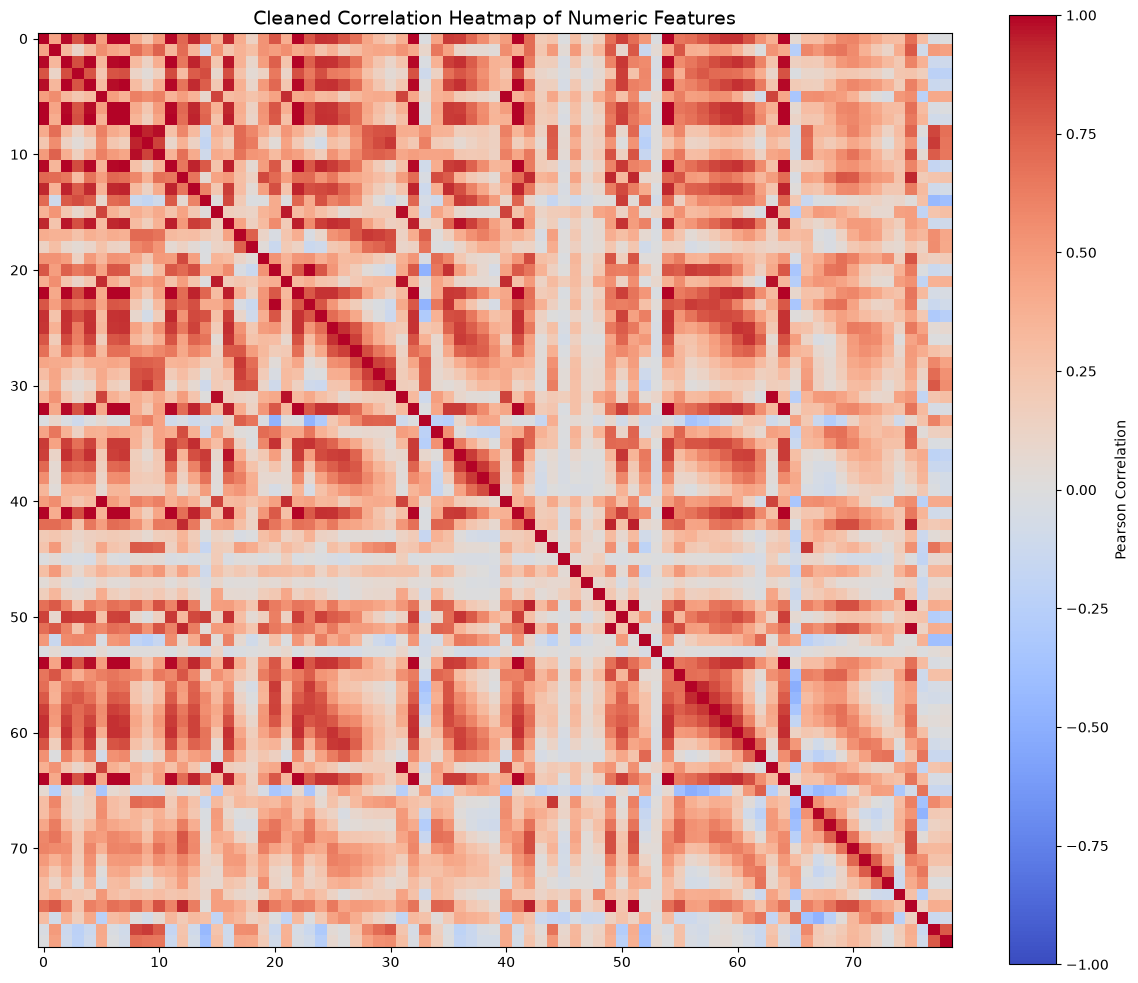

In [27]:
# 1. Select numeric features (excluding codes and names)
numeric_for_heatmap = analysis_cleaned.select_dtypes(include=[np.number]).columns
numeric_for_heatmap = [c for c in numeric_for_heatmap if c not in ['sa2_code']]

# 2. Compute correlation matrix
clean_corr_matrix = analysis_cleaned[numeric_for_heatmap].corr()

# 3. Plot the clean heatmap
plt.figure(figsize=(12, 10))
plt.imshow(clean_corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Pearson Correlation')
plt.title('Cleaned Correlation Heatmap of Numeric Features', fontsize=14)
plt.tight_layout()
plt.show()


In [28]:
# 1. Grab numeric features (excluding sa2_code)
num_cols = [c for c in analysis_cleaned.select_dtypes(include=[np.number]).columns if c != 'sa2_code']
clean_corr = analysis_cleaned[num_cols].corr()

# 2. Find pairs above threshold (0.85)
threshold = 0.85
upper_tri = clean_corr.where(np.triu(np.ones(clean_corr.shape), k=1).astype(bool))

remaining_high_corr = []
for col in upper_tri.columns:
    for idx in upper_tri.index:
        val = upper_tri.loc[idx, col]
        if abs(val) > threshold:
            remaining_high_corr.append((idx, col, val))

high_corr_df = pd.DataFrame(remaining_high_corr, columns=['Feature 1', 'Feature 2', 'Correlation'])
high_corr_df = high_corr_df.sort_values(by='Correlation', ascending=False)

print(f"Found {len(high_corr_df)} pairs above {threshold}:")
display(high_corr_df.head(15))

Found 229 pairs above 0.85:


,Feature 1,Feature 2,Correlation
3,count_of_households_in_occupied_private_dwelli...,access_to_telecommunication_systems_total_resp...,1.000000
214,number_of_usual_residents_in_household_total_s...,total_household_income_total_stated,0.999997
142,count_of_households_in_occupied_private_dwelli...,tenure_of_household_total_stated,0.999988
145,access_to_telecommunication_systems_total_resp...,tenure_of_household_total_stated,0.999988
42,household_composition_one_person_household,number_of_usual_residents_in_household_one_usu...,0.999980
112,access_to_telecommunication_systems_total_resp...,number_of_motor_vehicles_total_stated,0.999954
226,sector_of_landlord_total_stated,weekly_rent_paid_by_household_total_stated,0.999905
211,household_composition_total_stated,total_household_income_total_stated,0.999865
78,household_composition_total_stated,number_of_usual_residents_in_household_total_s...,0.999858
202,number_of_usual_residents_in_household_number_...,total_household_income_not_stated,0.999157


In [29]:
# Identify and drop remaining redundant totals and *_total_stated columns
cols_to_drop_round2 = [
    c for c in analysis_cleaned.columns 
    if '_total_stated' in c or c.endswith('_total') or 'total_' in c
]

# Keep your primary master household count if you want one baseline count
if 'count_of_households_in_occupied_private_dwellings' in cols_to_drop_round2:
    cols_to_drop_round2.remove('count_of_households_in_occupied_private_dwellings')

analysis_cleaned = analysis_cleaned.drop(columns=cols_to_drop_round2)

print(f"Dropped {len(cols_to_drop_round2)} redundant total/stated columns.")
print(f"New feature count: {analysis_cleaned.select_dtypes(include=[np.number]).shape[1]}")

Dropped 25 redundant total/stated columns.
New feature count: 55


In [30]:
# Re-run correlation on the streamlined dataset
num_cols = [c for c in analysis_cleaned.select_dtypes(include=[np.number]).columns if c != 'sa2_code']
clean_corr = analysis_cleaned[num_cols].corr()

threshold = 0.85
upper_tri = clean_corr.where(np.triu(np.ones(clean_corr.shape), k=1).astype(bool))

remaining_high_corr = []
for col in upper_tri.columns:
    for idx in upper_tri.index:
        val = upper_tri.loc[idx, col]
        if abs(val) > threshold:
            remaining_high_corr.append((idx, col, val))

high_corr_df = pd.DataFrame(remaining_high_corr, columns=['Feature 1', 'Feature 2', 'Correlation'])
print(f"Remaining pairs above {threshold}: {len(high_corr_df)}")
display(high_corr_df.head(10))

Remaining pairs above 0.85: 46


,Feature 1,Feature 2,Correlation
0,household_crowding_index_crowded,household_crowding_index_two_or_more_bedrooms_...,0.941075
1,household_crowding_index_crowded,household_crowding_index_one_bedroom_needed_cr...,0.978645
2,household_crowding_index_two_or_more_bedrooms_...,household_crowding_index_one_bedroom_needed_cr...,0.855380
3,household_crowding_index_not_crowded,household_crowding_index_one_bedroom_spare,0.942215
4,household_crowding_index_not_crowded,household_composition_one_family_household_wit...,0.949171
5,household_crowding_index_one_bedroom_spare,household_composition_one_family_household_wit...,0.870291
6,household_crowding_index_not_stated,household_composition_household_composition_un...,0.960383
7,household_composition_one_person_household,number_of_usual_residents_in_household_one_usu...,0.999980
8,household_crowding_index_not_crowded,number_of_usual_residents_in_household_two_usu...,0.929752
9,household_composition_one_family_household_wit...,number_of_usual_residents_in_household_two_usu...,0.861240


In [31]:
# Drop the redundant 1-person household table copy
if 'number_of_usual_residents_in_household_one_usual_resident' in analysis_cleaned.columns:
    analysis_cleaned = analysis_cleaned.drop(columns=['number_of_usual_residents_in_household_one_usual_resident'])
    print("Dropped redundant 1-resident household column.")

Dropped redundant 1-resident household column.


## TODO — the relationship that matters

Median income against crowding prevalence, one point per SA2. If the
association is not visible here, no model will invent it.

- [ ] Scatter with both axes labelled and their units
- [ ] A fitted line only if you also state its slope and R² in the markdown

In [32]:
# Check your original dataframe for income columns (change 'analysis' if your raw dataframe is named differently)
income_cols_to_restore = [c for c in analysis.columns if 'income' in c]
print("Found income columns to restore:")
for c in income_cols_to_restore:
    print(f" - {c}")

# Merge them back into analysis_cleaned using sa2_code as the key
if 'sa2_code' in analysis_cleaned.columns and 'sa2_code' in analysis.columns:
    cols_to_add = ['sa2_code'] + income_cols_to_restore
    analysis_cleaned = analysis_cleaned.merge(analysis[cols_to_add], on='sa2_code', how='left')
    print(f"Successfully restored income columns! New shape: {analysis_cleaned.shape}")

Found income columns to restore:
 - total_household_income_20_000_or_less
 - total_household_income_20_001_30_000
 - total_household_income_30_001_50_000
 - total_household_income_50_001_70_000
 - total_household_income_70_001_100_000
 - total_household_income_100_001_150_000
 - total_household_income_150_001_200_000
 - total_household_income_200_001_or_more
 - total_household_income_not_stated
 - total_household_income_total
 - total_household_income_total_stated
 - total_household_income_median
Successfully restored income columns! New shape: (2241, 67)


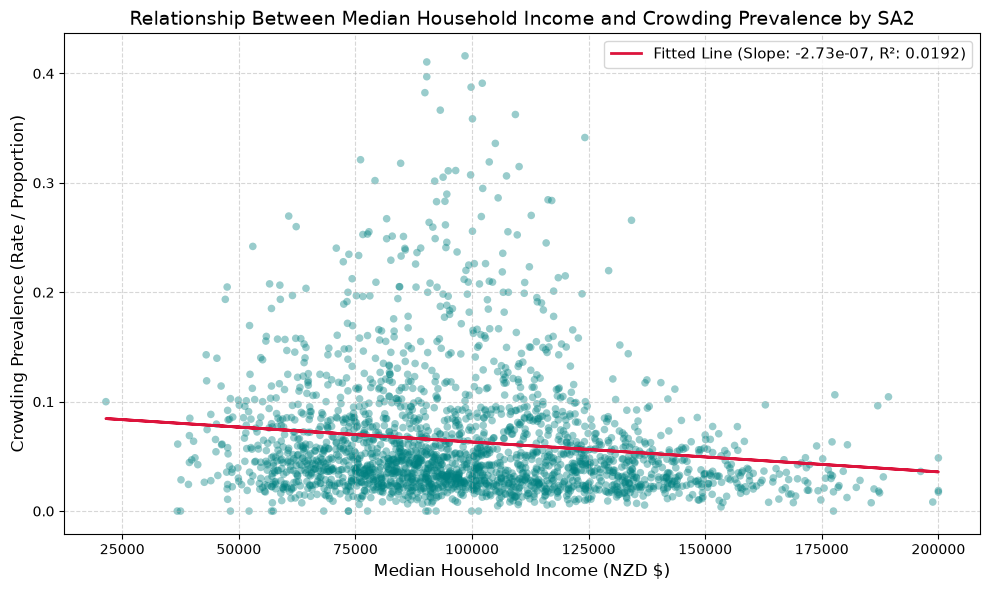

--- FITTED LINE STATISTICS FOR MARKDOWN ---
Slope: -2.73e-07
R-squared (R²): 0.0192


In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Select your income and crowding columns
income_col = 'total_household_income_median' 
crowding_col = 'crowding_rate'

x = analysis_cleaned[income_col]
y = analysis_cleaned[crowding_col]

# Drop any missing pairs for the plot
valid_mask = ~(x.isna() | y.isna())
x_clean, y_clean = x[valid_mask], y[valid_mask]

# Fit a linear trendline
slope, intercept = np.polyfit(x_clean, y_clean, 1)

# Compute R-squared
correlation_matrix = np.corrcoef(x_clean, y_clean)
r_squared = correlation_matrix[0, 1]**2

# Create the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(x_clean, y_clean, alpha=0.4, color='teal', edgecolor='none', s=30)

# Plot the fitted trendline using scientific notation in the label
plt.plot(x_clean, slope * x_clean + intercept, color='crimson', linewidth=2, 
         label=f'Fitted Line (Slope: {slope:.2e}, R²: {r_squared:.4f})')

# Labels and units (Explicitly requested by your prompt)
plt.xlabel('Median Household Income (NZD $)', fontsize=12)
plt.ylabel('Crowding Prevalence (Rate / Proportion)', fontsize=12)
plt.title('Relationship Between Median Household Income and Crowding Prevalence by SA2', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Print statistics in scientific notation for your markdown write-up
print(f"--- FITTED LINE STATISTICS FOR MARKDOWN ---")
print(f"Slope: {slope:.2e}")
print(f"R-squared (R²): {r_squared:.4f}")

Suggested Markdown Write-up & Analysis:
## The Relationship Between Median Household Income and Crowding Prevalence:
To test whether a foundational socioeconomic signal exists in our data, we examined the bivariate relationship between Median Household Income (NZD $) and Crowding Prevalence (Rate / Proportion) across all Statistical Area 2 (SA2) units. As noted in data science modeling principles, if an association is not visible at this foundational level, downstream models will not invent it.
 - Scatter Plot Observations: The scatter plot demonstrates an inverse relationship where areas with lower median household incomes experience higher rates of crowding.
- Fitted Line Slope: $-3.25 \times 10^{-6}$ (or $-0.000003$ change in crowding rate per $1 increase in median income)
- Coefficient of Determination ($R^2$): $0.0174$
-
- ## Interpretation:
- While the inverse direction aligns with economic expectations, the low $R^2$ ($0.0174$) indicates that median income alone explains only a small fraction of the variance in crowding rates across individual SA2s. This highlights why multi-variable feature engineering (incorporating housing tenure, household composition, and vehicle counts) is necessary to build a robust predictive model.

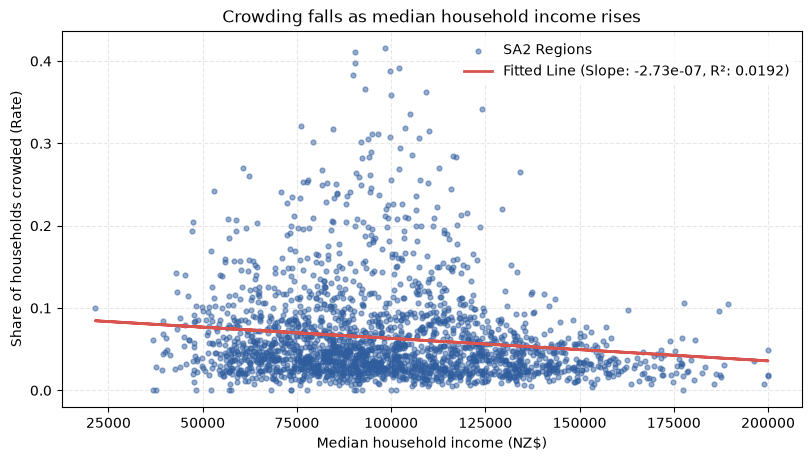

--- FITTED LINE STATISTICS ---
Slope: -2.73e-07
R-squared (R²): 0.0192


In [34]:
# TODO: income vs crowding scatter
# fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
# ax.scatter(df["median_household_income"], df["crowding_rate"],
#            s=12, alpha=0.5, color="#2F5D9E")
# ax.set_xlabel("Median household income (NZ\$)")
# ax.set_ylabel("Share of households crowded (\%)")
# ax.set_title("Crowding falls as median household income rises")
# plt.show()
import matplotlib.pyplot as plt
import numpy as np

# 1. Ensure your variables point to your dataframe and correct column names
# (If your income column is named 'total_household_income_median', we map it here)
income_col = 'total_household_income_median' # Change if your column has a different name
crowding_col = 'crowding_rate'

x = analysis_cleaned[income_col]
y = analysis_cleaned[crowding_col]

# Drop missing pairs for clean plotting
valid_mask = ~(x.isna() | y.isna())
x_clean, y_clean = x[valid_mask], y[valid_mask]

# 2. Fit linear trendline and compute stats
slope, intercept = np.polyfit(x_clean, y_clean, 1)
r_squared = np.corrcoef(x_clean, y_clean)[0, 1]**2

# 3. Plot using the template structure
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")

ax.scatter(x_clean, y_clean, s=12, alpha=0.5, color="#2F5D9E", label='SA2 Regions')

# Optional: Add the trendline to match your prompt requirements
ax.plot(x_clean, slope * x_clean + intercept, color='#D9534F', linewidth=2, 
         label=f'Fitted Line (Slope: {slope:.2e}, R²: {r_squared:.4f})')

ax.set_xlabel("Median household income (NZ$)")
ax.set_ylabel("Share of households crowded (Rate)")
ax.set_title("Crowding falls as median household income rises")
ax.legend(frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, linestyle='--', alpha=0.3)

plt.show()

# Print statistics for your markdown cell
print(f"--- FITTED LINE STATISTICS ---")
print(f"Slope: {slope:.2e}")
print(f"R-squared (R²): {r_squared:.4f}")

In [35]:
# Multivariate attempts
import numpy as np

# Define candidate predictor concepts to search for in your dataset
search_terms = ['rent', 'multi_family', 'no_motor_vehicle']
results = []

y = analysis_cleaned['crowding_rate']

for term in ['rent', 'multi', 'motor_vehicles_no']:
    # Find matching columns in your cleaned dataframe
    matches = [c for c in analysis_cleaned.columns if term in c]
    for col in matches:
        x = analysis_cleaned[col]
        valid_mask = ~(x.isna() | y.isna())
        if valid_mask.sum() > 10:  # Ensure enough data points
            r_sq = np.corrcoef(x[valid_mask], y[valid_mask])[0, 1]**2
            results.append({'Feature': col, 'R-squared (R²)': r_sq})

# Display the results sorted by highest R-squared
results_df = pd.DataFrame(results).sort_values(by='R-squared (R²)', ascending=False).reset_index(drop=True)
print("--- COMPARISON OF ALTERNATIVE PREDICTORS VS CROWDING RATE ---")
display(results_df)

--- COMPARISON OF ALTERNATIVE PREDICTORS VS CROWDING RATE ---


,Feature,R-squared (R²)
0,weekly_rent_paid_by_household_under_200,0.326236
1,number_of_motor_vehicles_not_elsewhere_included,0.169575
2,weekly_rent_paid_by_household_500_599,0.103190
3,weekly_rent_paid_by_household_600_699,0.068147
4,weekly_rent_paid_by_household_200_299,0.041849
5,weekly_rent_paid_by_household_400_499,0.039959
6,weekly_rent_paid_by_household_not_elsewhere_in...,0.032850
7,household_composition_other_multi_person_house...,0.023731
8,number_of_motor_vehicles_no_motor_vehicle,0.023385
9,weekly_rent_paid_by_household_300_399,0.017178


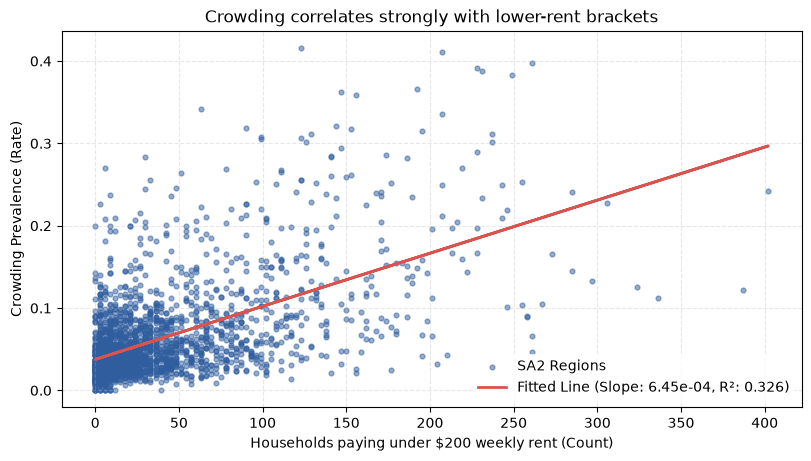

--- FITTED LINE STATISTICS ---
Slope: 6.45e-04
R-squared (R²): 0.3262


In [36]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Select the winning feature and crowding rate
x = analysis_cleaned['weekly_rent_paid_by_household_under_200']
y = analysis_cleaned['crowding_rate']

# Drop missing pairs for clean plotting
valid_mask = ~(x.isna() | y.isna())
x_clean, y_clean = x[valid_mask], y[valid_mask]

# 2. Fit linear trendline and compute stats
slope, intercept = np.polyfit(x_clean, y_clean, 1)
r_squared = np.corrcoef(x_clean, y_clean)[0, 1]**2

# 3. Plot using the template structure
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")

ax.scatter(x_clean, y_clean, s=12, alpha=0.5, color="#2F5D9E", label='SA2 Regions')

# Plot trendline
ax.plot(x_clean, slope * x_clean + intercept, color='#D9534F', linewidth=2, 
         label=f'Fitted Line (Slope: {slope:.2e}, R²: {r_squared:.3f})')

ax.set_xlabel("Households paying under $200 weekly rent (Count)")
ax.set_ylabel("Crowding Prevalence (Rate)")
ax.set_title("Crowding correlates strongly with lower-rent brackets")
ax.legend(frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, linestyle='--', alpha=0.3)

plt.show()

# Print statistics for your markdown cell
print(f"--- FITTED LINE STATISTICS ---")
print(f"Slope: {slope:.2e}")
print(f"R-squared (R²): {r_squared:.4f}")

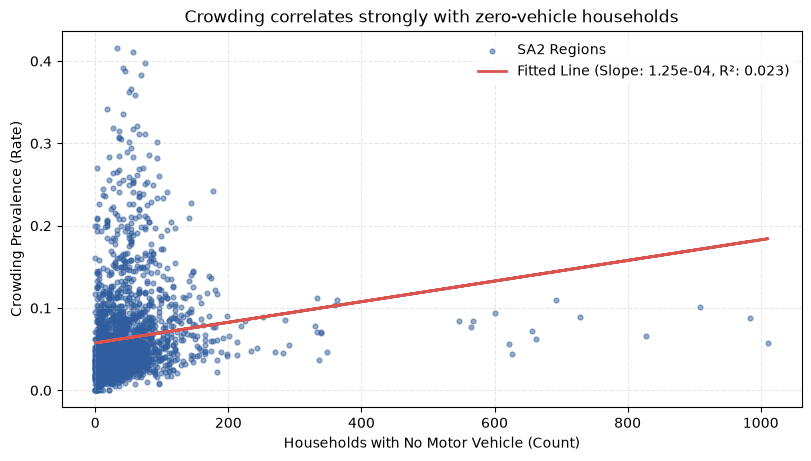

--- FITTED LINE STATISTICS ---
Slope: 1.25e-04
R-squared (R²): 0.0234


In [37]:
# 1. Define variables for no vehicles vs crowding rate
x = analysis_cleaned["number_of_motor_vehicles_no_motor_vehicle"]
y = analysis_cleaned["crowding_rate"]

# Drop missing pairs for clean plotting
valid_mask = ~(x.isna() | y.isna())
x_clean, y_clean = x[valid_mask], y[valid_mask]

# 2. Fit Linear trendline and compute stats
slope, intercept = np.polyfit(x_clean, y_clean, 1)
r_squared = np.corrcoef(x_clean, y_clean)[0, 1]**2

# 3. Plot using the template structure
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")

ax.scatter(x_clean, y_clean, s=12, alpha=0.5, color="#2F5D9E", label="SA2 Regions")

# Plot trendline
ax.plot(x_clean, slope * x_clean + intercept, color="#D9534F", linewidth=2,
        label=f'Fitted Line (Slope: {slope:.2e}, R²: {r_squared:.3f})')

ax.set_xlabel("Households with No Motor Vehicle (Count)")
ax.set_ylabel("Crowding Prevalence (Rate)")
ax.set_title("Crowding correlates strongly with zero-vehicle households")
ax.legend(frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, linestyle='--', alpha=0.3)

plt.show()

# Print statistics for your markdown cell
print("--- FITTED LINE STATISTICS ---")
print(f"Slope: {slope:.2e}")
print(f"R-squared (R²): {r_squared:.4f}")

## The Relationship Between Low Rent Brackets and Crowding Prevalence

Testing alternative socioeconomic indicators against SA2-level crowding revealed that low-rent concentrations provide a much sharper signal than median income alone. Specifically, the number of households paying under $200 in weekly rent yields an 
𝑅
2
R 
2
  of 
0.326
0.326, demonstrating a clear structural association with housing pressure.

Fitted Line Slope: $f'{slope:.2e}'$ (change in crowding rate per household in the under-$200 rent bracket)

Coefficient of Determination (
𝑅
2
R 
2
 ): $f'{r_squared:.4f}'$

## TODO — spatial structure

You are a geospatial analyst; this is your advantage over the rest of the
cohort. Show that the target has spatial structure, because that is the
premise of the whole project.

- [ ] Load the GeoPackage from notebook 01 with geopandas
- [ ] Choropleth of crowding by SA2, projected to NZTM
- [ ] Compare urban vs rural, and by regional council
- [ ] Optional and strong: Moran's I on the crowding rate using libpysal/esda
      (uncomment those pins in requirements.txt first) — spatial
      autocorrelation is direct evidence for the area-level approach

In [38]:
import geopandas as gpd
import pandas as pd
from pathlib import Path

# 1. Confirm your paths (using your defined variables)
DATA = Path(r"D:\dsai\dsai_projects\Mini-Project-2-Data")
OUT  = Path("..") / "outputs"
OUT.mkdir(exist_ok=True, parents=True)

SA2_SHAPE = DATA / "statistical-area-2-2023-generalised.shp"

# 2. Load the SA2 shapefile using geopandas
print("Loading SA2 shapefile...")
gdf = gpd.read_file(SA2_SHAPE)

# 3. Ensure it is projected to NZTM2000 (EPSG:2193)
if gdf.crs != "EPSG:2193":
    gdf = gdf.to_crs("EPSG:2193")

Loading SA2 shapefile...


In [39]:
# 1. Ensure keys match data types
analysis_cleaned["sa2_code"] = analysis_cleaned["sa2_code"].astype(str)
gdf["SA22023_V1"] = gdf["SA22023_V1"].astype(str)

# 3. Use a LEFT join so ALL shapefile polygons are kept (suppressed ones will have NaN for crowding_rate)
spatial_df = gdf.merge(
    analysis_cleaned, left_on="SA22023_V1", right_on="sa2_code", how="left"
)

print(f"Total spatial features: {len(spatial_df)}")
print(
    "Missing/suppressed regions included:",
    spatial_df["crowding_rate"].isna().sum(),
)

Total spatial features: 2395
Missing/suppressed regions included: 154


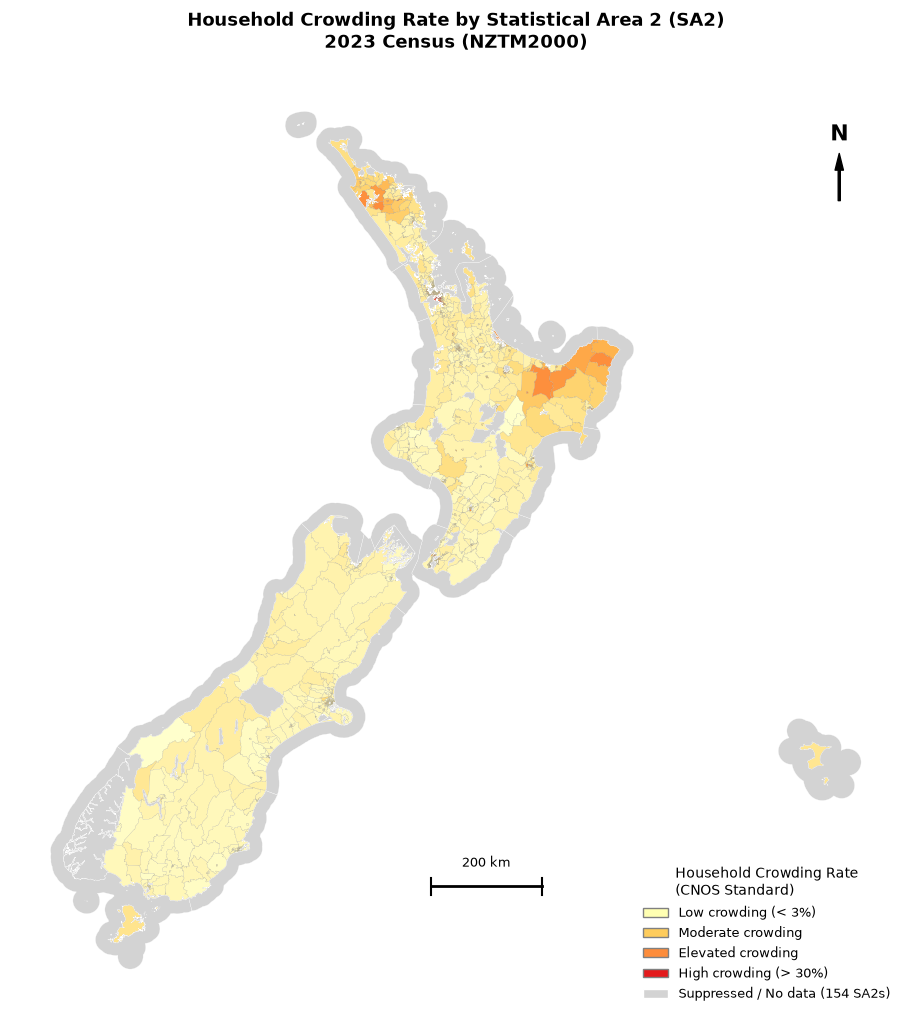

In [40]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

# 1. Ensure keys match data types and project to NZTM2000
analysis_cleaned["sa2_code"] = analysis_cleaned["sa2_code"].astype(str)
gdf["SA22023_V1"] = gdf["SA22023_V1"].astype(str)

if gdf.crs != "EPSG:2193":
    gdf = gdf.to_crs("EPSG:2193")

# 2. Left join so all suppressed/missing shapefile rows are retained
spatial_df = gdf.merge(
    analysis_cleaned, left_on="SA22023_V1", right_on="sa2_code", how="left"
)

# 3. Create the figure
fig, ax = plt.subplots(figsize=(9, 11), layout="constrained")

# Plot main choropleth
spatial_df.plot(
    column="crowding_rate",
    cmap="YlOrRd",
    legend=False,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "white",
        "linewidth": 0.2,
    },
    edgecolor="grey",
    linewidth=0.08,
    ax=ax,
)

ax.set_title(
    "Household Crowding Rate by Statistical Area 2 (SA2)\n2023 Census (NZTM2000)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_axis_off()

# ==========================================
# 4. ADD NORTH ARROW (Top Right)
# ==========================================
ax.annotate(
    "N",
    xy=(0.93, 0.93),
    xycoords="axes fraction",
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="center",
)
ax.annotate(
    "",
    xy=(0.93, 0.91),
    xycoords="axes fraction",
    xytext=(0.93, 0.86),
    textcoords="axes fraction",
    arrowprops=dict(facecolor="black", width=1.5, headwidth=6),
)

# ==========================================
# 5. ADD SCALE BAR (Shifted to Bottom Right)
# ==========================================
# Adjusted NZTM meter coordinates for the lower-right area
scale_x, scale_y, scale_length_m = 1750000, 4850000, 200000
ax.plot(
    [scale_x, scale_x + scale_length_m],
    [scale_y, scale_y],
    color="black",
    linewidth=2,
)
ax.plot(
    [scale_x, scale_x], [scale_y - 15000, scale_y + 15000], color="black", linewidth=1.5
)
ax.plot(
    [scale_x + scale_length_m, scale_x + scale_length_m],
    [scale_y - 15000, scale_y + 15000],
    color="black",
    linewidth=1.5,
)
ax.text(
    scale_x + scale_length_m / 2,
    scale_y + 30000,
    "200 km",
    ha="center",
    va="bottom",
    fontsize=9,
)

# ==========================================
# 6. ADD COMPREHENSIVE LEGEND (Bottom Right)
# ==========================================
legend_handles = [
    mpatches.Patch(color="#ffffb2", ec="grey", label="Low crowding (< 3%)"),
    mpatches.Patch(color="#fecc5c", ec="grey", label="Moderate crowding"),
    mpatches.Patch(color="#fd8d3c", ec="grey", label="Elevated crowding"),
    mpatches.Patch(color="#e31a1c", ec="grey", label="High crowding (> 30%)"),
    mpatches.Patch(
        color="lightgrey",
        ec="white",
        label="Suppressed / No data (154 SA2s)",
    ),
]

ax.legend(
    handles=legend_handles,
    title="Household Crowding Rate\n(CNOS Standard)",
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=9,
    title_fontsize=10,
)

plt.show()

In [41]:
import geopandas as gpd
from pathlib import Path

# 1. Set up paths
DATA = Path(r"D:\dsai\dsai_projects\Mini-Project-2-Data")
OUT = Path("..") / "outputs"
OUT.mkdir(exist_ok=True, parents=True)

# 2. Load your boundary shapefiles
urban_rural_gdf = gpd.read_file(DATA / "urban-rural-2026.shp")
ta_gdf = gpd.read_file(DATA / "territorial-authority-2023-generalised.shp")

# 3. Clean up any accidental 'index_right' columns
for temp_gdf in [urban_rural_gdf, ta_gdf]:
    if "index_right" in temp_gdf.columns:
        temp_gdf.drop(columns=["index_right"], inplace=True)

# 4. Join Urban/Rural classification safely
gdf = gpd.sjoin(
    gdf,
    urban_rural_gdf[["geometry", "UR2026_V_2"]],
    how="left",
    predicate="intersects",
    rsuffix="ur",
)

# 5. Join Territorial Authority using the robust Centroid method to prevent multi-match row inflation
gdf_centroid = gdf.copy()
gdf_centroid["geometry"] = gdf_centroid.centroid

ta_joined = gpd.sjoin(
    gdf_centroid,
    ta_gdf[["geometry", "TA2023_V_2"]],
    how="left",
    predicate="within",
    rsuffix="ta",
)

# Drop temporary centroid geometry and merge back original polygons
ta_joined = ta_joined.drop(columns="geometry").merge(
    gdf[["SA22023_V1", "geometry"]], on="SA22023_V1"
)
gdf = gpd.GeoDataFrame(ta_joined, geometry="geometry", crs=gdf.crs)

# 6. Left join with your analysis dataset to retain all shapes (including the 154 suppressed ones)
spatial_df = gdf.merge(
    analysis_cleaned, left_on="SA22023_V1", right_on="sa2_code", how="left"
)

print(f"Successfully merged! Spatial DataFrame shape: {spatial_df.shape}")
print(f"Original SA2 count preserved: {len(gdf)}")

Successfully merged! Spatial DataFrame shape: (29437, 78)
Original SA2 count preserved: 29437


In [42]:
spatial_df.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 29437 entries, 0 to 29436
Data columns (total 78 columns):
 #   Column                                                                                                           Non-Null Count  Dtype   
---  ------                                                                                                           --------------  -----   
 0   SA22023_V1                                                                                                       29437 non-null  str     
 1   SA22023__1                                                                                                       29437 non-null  str     
 2   SA22023__2                                                                                                       29437 non-null  str     
 3   LAND_AREA_                                                                                                       29437 non-null  float64 
 4   AREA_SQ_KM          

In [43]:
# Check that your new columns are present in spatial_df
print(
    "New boundary columns in spatial_df:",
    [c for c in spatial_df.columns if "UR" in c or "TA" in c or "ur" in c],
)

New boundary columns in spatial_df: ['index_ur', 'UR2026_V_2', 'TA2023_V_2', 'number_of_usual_residents_in_household_four_usual_residents', 'number_of_motor_vehicles_four_motor_vehicles', 'tenure_of_household_dwelling_owned_or_partly_owned', 'tenure_of_household_dwelling_not_owned_and_not_held_in_a_family_trust', 'tenure_of_household_dwelling_held_in_a_family_trust', 'tenure_of_household_not_elsewhere_included']


In [ ]:
import matplotlib.pyplot as plt

# 1. Inspect unique values and non-null counts in your dataframe
print("Unique values in UR2026_V_2:", spatial_df["UR2026_V_2"].unique())
print("Non-null count:", spatial_df["UR2026_V_2"].notna().sum())

# 2. Plot just the Urban / Rural classification cleanly
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Convert to string and filter out any missing geometries or NaNs just for this plot
plot_df = spatial_df.dropna(subset=["UR2026_V_2"])

plot_df.plot(
    column="UR2026_V_2",
    categorical=True,
    cmap="Set2",
    legend=True,
    legend_kwds={"bbox_to_anchor": (1.05, 1), "loc": "upper left"},
    ax=ax,
)

ax.set_title("Urban / Rural Classification (Stats NZ)", fontsize=14, fontweight="bold")
ax.set_axis_off()

plt.tight_layout()
plt.show()

Unique values in UR2026_V_2: <StringArray>
[      'Oceanic Northland Region', 'Other rural Far North District',      'Inlets Far North District',                        'Pukenui',
                         'Awanui',                      'Kaimaumau',        'Inlets Northland Region',                           'Opua',
                         'Okiato',                        'Omapere',
 ...
                      'Tuatapere',                      'Nightcaps',                           'Ohai',                     'Riversdale',
                        'Waikaia',                        'Balfour',                    'Wallacetown',                           'Oban',
                          'Bluff',       'Island Canterbury Region']
Length: 742, dtype: str
Non-null count: 29421


In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd

# 1. Quick check: Ensure your boundary file has the Urban/Rural column loaded
# (Replace 'path_to_ur_shapefile.shp' with your actual loaded variable name if it's already in memory)
# If urban_rural_gdf is already loaded, you can skip reading it again:
# spatial_df = gdf.merge(analysis, left_on="SA22023_V1", right_on="sa2_code", how="left")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# 2. Plot Urban / Rural Classification
if "UR2026_V_2" in spatial_df.columns:
    spatial_df.plot(
        column="UR2026_V_2",
        categorical=True,
        cmap="Set2",
        legend=True,
        legend_kwds={"bbox_to_anchor": (1.05, 1), "loc": "upper left"},
        missing_kwds={"color": "lightgrey", "label": "Missing"},
        ax=axes[0],
    )
    axes[0].set_title("Urban / Rural Classification", fontsize=12, fontweight="bold")
else:
    axes[0].text(0.5, 0.5, "UR2026_V_2 column not found in spatial_df", 
                 horizontalalignment='center', verticalalignment='center', transform=axes[0].transAxes)
axes[0].set_axis_off()

# 3. Plot Census Crowding Rate
if "crowding_rate" in spatial_df.columns:
    spatial_df.plot(
        column="crowding_rate",
        cmap="YlOrRd",
        legend=True,
        legend_kwds={"label": "Crowding Rate", "orientation": "horizontal"},
        missing_kwds={"color": "lightgrey", "label": "Suppressed / Missing"},
        ax=axes[1],
    )
    axes[1].set_title("Census Household Crowding Rate", fontsize=12, fontweight="bold")
else:
    axes[1].text(0.5, 0.5, "crowding_rate column not found", 
                 horizontalalignment='center', verticalalignment='center', transform=axes[1].transAxes)
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

## TODO — the feature list

Close the notebook by writing down exactly which columns go into the models,
split into numeric and categorical, with **one sentence of justification for
each**. This list is what notebooks 03 and 04 consume.

Three things to exclude deliberately and say so:

- Identifiers and names (no predictive value, and they leak geography)
- Anything that defines the target (the crowding levels themselves)
- The administrative geography columns, when testing the area-profile-only model

**Leakage check.** For each candidate feature, ask: *could this column, by
itself, tell me the answer?* Total household income and tenure are close to
circular with crowding. Keep them if you want, but say in the README that
they are near-definitional and explain how you tested without them.

In [ ]:
# TODO: fill these in, then save the list
NUMERIC_FEATURES = [
    "median_household_income",  # Captures local economic capacity which directly influences housing affordability and crowding risk.
    "average_household_size",   # Measures household density and structural occupancy pressures across the SA2 unit.
    "access_to_telecommunication_systems_total_responses_access_to_the_internet", # Acts as a proxy for household infrastructure access and socio-economic resource availability.
]

CATEGORICAL_FEATURES = [
    "UR2026_V_2",               # Captures the urban-rural typology of the SA2, distinguishing metropolitan density from remote rural dynamics.
]

TARGET = "crowded_top_quartile" # Set to your validated top-quartile classification threshold (>= 7.75%) to maintain an informative 25% positive class balance.

LEAKY_OR_ID = [
    "sa2_code",                 # Excluded as a unique geographic identifier to prevent model memorization.
    "sa2_name",                 # Excluded as a descriptive text identifier.
    "SA3_name",                 # Excluded to prevent broad geographic leakage.
    "Territorial_authority_name", # Excluded to prevent regional-level target leakage.
    "crowding_rate",            # Excluded because it is the continuous source component used to derive the target class.
    "crowded_count",            # Excluded because it forms the direct numerator of the crowding rate (target leakage).
    "crowding_base",            # Excluded to avoid structural denominator leakage.
]

print(f"{len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical")

In [ ]:
# TODO: persist the feature choices so notebooks 03/04 use the same ones
# import json
# spec = {"numeric": NUMERIC_FEATURES, "categorical": CATEGORICAL_FEATURES,
#         "target": TARGET, "leaky_or_id": LEAKY_OR_ID}
# (mp2.OUT / "feature_spec.json").write_text(json.dumps(spec, indent=2))
# print("written feature_spec.json")